# Estimar ingresos laborales: ¿qué aportan las características del trabajo?
### Unidades 2, 3 y 4 · Laboratorio de Datos I · UNTDF

**Parcial E1 · Economía · Resolución individual domiciliaria · Plazo: dos semanas**

La Encuesta Permanente de Hogares permite relacionar educación, experiencia potencial y características laborales con el ingreso de la ocupación principal. Se explorará un recorte curado del cuarto trimestre de 2025 y se compararán una regresión lineal sencilla, una ampliada y alternativas Ridge.

**Pregunta central:** ¿agregar horas, sector y rama de actividad reduce el error de estimación del logaritmo del ingreso respecto de utilizar sólo educación y experiencia potencial?

Nombre y apellido: Tadeo Gonzalez Baima · Carrera: Ingenieria Industrial · Fecha de entrega: 05/10/2026


## Guía de trabajo

- Resolver las diez consignas C1–C10 en este archivo. Se pueden agregar celdas de código y texto conservando los títulos.
- La carga, las particiones y la codificación de categorías están provistas. El análisis, los modelos y las decisiones se completan en los espacios indicados.
- Usar sólo los CSV del paquete. No reconstruir la EPH ni agregar datos externos. Consultar el diccionario antes de tratar una categoría como número.
- Explorar exclusivamente entrenamiento. La validación se usa en C6 para comparar y en C7 para elegir. Abrir `prueba.csv` por primera vez en C8 y no volver a ajustar después.
- No realizar validación cruzada: se utiliza una validación fija. Elegir una sola lista de variables laborales antes de comparar; la búsqueda máxima es la que fija C6.
- Entregar el notebook ejecutado desde un kernel limpio, con interpretaciones, junto a `datasets/`. No se pide un informe separado. Superar una referencia no es condición de aprobación.

La primera celda prepara el entorno; las versiones probadas figuran en `requirements.txt`. Ejecutar el archivo vacío comprueba únicamente el soporte, no resuelve el examen.

Aclaracion sobre uso de IA: Hice uso de Claude como guia conceptual para interpretar algunas consignas y para escribir fragmentos de codigo.

In [1]:
# Bloque de codigo agregado --> Entorno para montar Drive y ubicarse en la carpeta del parcial
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/E1-Tadeo")
except ImportError:
    pass

print("Carpeta actual:", os.getcwd())
print("Contenido:", os.listdir())

Mounted at /content/drive
Carpeta actual: /content/drive/MyDrive/E1-Tadeo
Contenido: ['DICCIONARIO.md', 'FUENTES_Y_LICENCIAS.md', 'README.md', 'requirements.txt', 'datasets', 'Programa Laboratorio de Datos I.pdf', 'E1_Parcial_ingresos_laborales.ipynb']


In [2]:
# === Setup de la cátedra — Laboratorio de Datos I (UNTDF) ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from importlib.metadata import version

SEED = 42
rng = np.random.default_rng(SEED)

# Paleta de la cátedra (fondo claro) — usar por semántica, no por gusto
AZUL   = "#4A7A9B"  # serie base
CIAN   = "#5AA9D6"  # serie secundaria / estructura
DORADO = "#D8A24A"  # transición
AMBAR  = "#E89340"  # único acento: lo que sostiene la conclusión
GRIS   = "#B9C4CE"  # contexto / referencia
TINTA  = "#0E1620"  # texto, ejes y bordes
PROGRESION = [AZUL, CIAN, DORADO, AMBAR]

plt.rcParams.update({
    "figure.figsize": (11.5, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRIS, "grid.alpha": 0.35,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "text.color": TINTA, "axes.labelcolor": TINTA, "axes.edgecolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
    "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[AZUL, AMBAR, CIAN, DORADO, GRIS]),
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

**Interpretación.** Se fijan la semilla y la paleta. Todas las importaciones se concentran en esta celda; incorporar aquí cualquier herramienta adicional que se necesite.

# 1. Comprender el ingreso y la población observada
## 1.1 Contexto y vocabulario mínimo

La **EPH** releva hogares y personas de aglomerados urbanos. Cada fila de este paquete representa una persona ocupada de 16 a 70 años, con ingreso positivo de la ocupación principal y horas semanales válidas y positivas. Se usan todos los aglomerados presentes en ese trimestre; no se trata de una muestra exclusiva de Tierra del Fuego.

El ingreso `P21` se conserva en pesos argentinos nominales del período: es el ingreso habitual de la ocupación principal, no el ingreso total del hogar ni necesariamente un salario. Una persona por cuenta propia también puede tener este ingreso. Las horas corresponden a esa ocupación durante la semana de referencia. El modelo es una **estimación contemporánea**, no un pronóstico de otro trimestre.

**Glosario.** *Ocupación principal*: actividad tomada como principal en la encuesta. *Sector*: carácter estatal, privado u otro de la unidad donde se trabaja. *Rama*: actividad del establecimiento, agrupada por la cátedra. *Experiencia potencial*: aproximación construida con edad y educación; no es antigüedad laboral observada. *Vivienda*: unidad identificada por CODUSU que puede contener más de un hogar.

El objetivo es `log_ingreso`, obtenido con el logaritmo natural de `P21`. La escala logarítmica comprime diferencias monetarias grandes: un error de una unidad logarítmica no equivale a un peso ni a un punto porcentual. Se evaluará en esta escala. Exponenciar una predicción permite una comparación ilustrativa en pesos, pero no recupera automáticamente el ingreso medio condicional.

La educación se aproxima por una convención didáctica, no por años observados: sin instrucción 0; primaria incompleta 3; primaria completa 7; secundaria incompleta 10; secundaria completa 12; superior incompleta 14; superior completa 17. La experiencia potencial es `max(edad − años de educación − 6, 0)` y se incluye también su cuadrado. Estas aproximaciones simplifican trayectorias reales.

Lecturas seleccionadas, con dedicación contextual total máxima de 3–4 horas:

1. [INDEC: diseño de registro EPH 4T2025](https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/EPH_registro_4T2025.pdf): páginas impresas 4, 14–18, 20–21 y 34–35. Consultar sólo identificación, educación, trabajo, ingreso y no respuesta.
2. [INDEC: acceso a las bases](https://www.indec.gob.ar/Institucional/Indec/BasesDeDatos): introducción de EPH y apartado cuarto trimestre de 2025. No es necesario descargar ni estudiar otros trimestres.

**Vocabulario de modelado.** Variable objetivo (*target*): lo que se estima; variable predictora (*feature*): información usada para estimarlo. Entrenamiento (*training*) ajusta el modelo; validación (*validation*) permite elegirlo; prueba (*test*) evalúa la elección congelada. El análisis exploratorio de datos (EDA, *exploratory data analysis*) usa sólo entrenamiento. Una secuencia de transformaciones y modelo (*pipeline*, `Pipeline`) aprende la preparación junto con el estimador; aprender con datos reservados produciría filtración de información (*data leakage*). `alpha` es un hiperparámetro (*hyperparameter*) de Ridge. La codificación por indicadores (*one-hot encoding*) representa categorías sin ordenarlas.


## 1.2 Diccionario y curación entregada

| Campo | Significado | Uso autorizado |
|---|---|---|
| `id_persona` | Identificador creado para el paquete | Auditoría/errores; no predictor |
| `grupo_vivienda` | Recodificación de CODUSU | Separación; no predictor |
| `edad_anios` | Edad observada en años | Auditoría y EDA |
| `sexo_registrado` | Varón/mujer según el registro de la encuesta | EDA y límites; no predictor |
| `nivel_educativo` | Nivel máximo agrupado | EDA; su aproximación numérica entra al modelo |
| `anios_educacion` | Años aproximados por la convención anterior | Predictor base |
| `experiencia_potencial` | Aproximación de experiencia en años | Predictor base |
| `experiencia_cuadrado` | Cuadrado de la experiencia potencial | Predictor base |
| `horas_semana` | Horas de la ocupación principal en semana de referencia | Menú laboral, numérica |
| `sector` | Estatal, privado, otro o no informado | Menú laboral, categórica |
| `rama_agrupada` | Agrupación pedagógica de actividad CAES | Menú laboral, categórica |
| `categoria_ocupacional` | Patrón, cuenta propia, asalariado u otra categoría | EDA; no predictor en este contrato |
| `region` | Región de los aglomerados | EDA y errores; no predictor |
| `ingreso_principal_ars` | P21 original positivo, pesos nominales | EDA; nunca predictor |
| `log_ingreso` | Logaritmo natural del ingreso | Objetivo |

La cátedra excluyó no respuestas de ingreso, ingresos cero y horas no válidas. En particular, `999` en horas es no respuesta, no una jornada extensa. No se imputó ingreso ni se eliminaron extremos positivos válidos. La tabla auxiliar `no_respuesta_ingreso.csv` describe la selección entre ocupados de 16–70 años antes de filtrar; no es un conjunto de entrenamiento adicional. Los códigos de rama no interpretados conservan una categoría explícita, sin adivinar una actividad.

Los microdatos no incluyen aquí ponderadores de encuesta. **Todas las estadísticas y métricas describen filas del recorte**, sin estimar salarios nacionales, totales poblacionales ni brechas causales. En particular, comparar regiones no elimina diferencias en su composición.

## 1.3 Consigna C1 — Formular una estimación delimitada

Completar la tabla. En un párrafo adicional explicar por qué este análisis no estima el efecto causal de estudiar un año más ni el ingreso medio de toda la Argentina.

| Elemento | Respuesta |
|---|---|
| Unidad de observación | Persona ocupada de 16 a 70 años, con ingreso positivo de la ocupación principal y horas semanales positivas y válidas correspondientes a su ocupación principal. |
| Objetivo y escala | El objetivo es el logaritmo natural del ingreso de la ocupación principal en pesos argentinos (log_ingreso). Se utilizará escala logarítmica para poder comprimir diferencias monetarias grandes, por lo que los errores van a quedar en escalas logaritmos.|
| Información disponible | Predictores base: anios_educacion, experiencia_potencial, experiencia_cuadrado ; Menu laboral: horas_semana, sector, rama_agrupada ; Filtracion: ingreso_principal_ars ; Identificadores de la persona: id_persona, grupo_vivienda ; EDA o auditoria: region, sexo_registrado, categoria_ocupacional, edad_anios, nivel educativo|
| Alcance de una conclusión válida | El alcance queda demarcado por ser una estimacion contemporánea, dado que no se estiman salarios a nivel país. Por lo tanto, podríamos llegar a concluir que el agregado de variables laborales predictoras (como las horas, sector y rama) pueden reducir los errores de estimación para esta muestra.|

**Límites de interpretación:** La asociación educación-ingreso no es el efecto de estudiar un año más dado que son datos observacionales: la educación no se asignó al azar, sino que cada persona llegó a su nivel por circunstancias propias. Existen incluso factores como las redes de contactos, el origen familiar, tipo de ocupación entre otras que no son observadas en el estudio y que guardan relación con la educación y el ingreso.
Además existe un sesgo de selección, solo vemos a aquellos quienes trabajan y declararon su ingreso.

Tampoco estima el ingreso medio del país ya que:
La variable objetivo solo mide el ingreso de la ocupación principal en pesos argentinos, no el ingreso total de la persona o del hogar.
El recorte excluye a aquellos que no respondieron, declararon ingreso cero, desocupados e inactivos, fuera de 16–70 y población rural. Estas exclusiones provienen de los criterios del recorte, no porque la variable mida la ocupación principal, por lo que la no respuesta puede no ser aleatoria.
En la EPH cada persona "representa" a una cantidad distinta de personas de la población. Sin esos pesos, promediar filas no da el promedio de la población ya que el paquete no incluye ponderadores.


# 2. Separar comparación y prueba
## 2.1 Un corte fijo que conserva viviendas completas

| Etapa | Datos | Operación |
|---|---|---|
| C3–C5 | Entrenamiento | Auditar, explorar, elegir variables y definir la preparación |
| C6 | Entrenamiento y validación | Ajustar sólo con entrenamiento; comparar errores en validación |
| C7 | Tabla de validación | Congelar una elección |
| C8–C9 | Prueba reservada | Evaluar una vez y explicar errores |

Las viviendas completas se asignaron aproximadamente 70/15/15 a entrenamiento, validación y prueba, mediante semilla 42. Los porcentajes de filas difieren levemente porque cada vivienda puede aportar varias personas. Los códigos de vivienda se entregan para controlar esta separación, no para aprender ingresos a partir de identificadores.

Después de elegir, se conserva el modelo ajustado con entrenamiento: **no se reajusta incorporando validación**. Las particiones no se cambian. El siguiente soporte carga sólo entrenamiento, validación y la tabla auxiliar de selección.

In [3]:
RUTA_DATOS = Path("datasets")
OBJETIVO = "log_ingreso"
BASE = ["anios_educacion", "experiencia_potencial", "experiencia_cuadrado"]
MENU_LABORAL = ["horas_semana", "sector", "rama_agrupada"]
if not (RUTA_DATOS / "entrenamiento.csv").is_file():
    raise FileNotFoundError("Abrir el notebook en la carpeta que contiene datasets/.")
entrenamiento = pd.read_csv(RUTA_DATOS / "entrenamiento.csv")
validacion = pd.read_csv(RUTA_DATOS / "validacion.csv")
no_respuesta = pd.read_csv(RUTA_DATOS / "no_respuesta_ingreso.csv")
assert set(entrenamiento.grupo_vivienda).isdisjoint(validacion.grupo_vivienda)
display(pd.DataFrame({"conjunto": ["entrenamiento", "validacion"],
                      "personas": [len(entrenamiento), len(validacion)],
                      "viviendas": [entrenamiento.grupo_vivienda.nunique(), validacion.grupo_vivienda.nunique()]}))

,conjunto,personas,viviendas
0,entrenamiento,10450,6899
1,validacion,2255,1478


**Interpretación.** El soporte informa tamaños y comprueba que no se comparten viviendas entre ajuste y validación. No muestra ingresos ni métricas de validación. La comprobación frente a prueba se realizará al abrirla en C8.

## 2.2 Consigna C2 — Justificar el contrato

1. Explicar por qué `ingreso_principal_ars`, `id_persona` y `grupo_vivienda` quedan fuera de los predictores, distinguiendo filtración de información e identificación.
2. Explicar por qué separar personas al azar podría repartir información dependiente entre entrenamiento y evaluación.
3. Indicar cuándo se ajustan el escalador y el codificador, y por qué volver a elegir tras observar prueba invalidaría su función.

Escribir la respuesta en este espacio.

1) ingreso_principal_ars queda fuera de los predictores ya que de lo contrario implicaría fuga de información, al ser la propia variable objetivo en otra escala, aplicando logaritmo natural. Por otro lado, id_persona y grupo_vivienda quedan fuera de los predictores ya que son campos que identifican a la persona o a su vivienda  y como tal no poseen significado económico en la estimación del log_ingreso. El ingreso es filtración, los id son identificación.

2) Porque corremos el riesgo de pasar dos veces casi el mismo dato al existir dependencia entre personas de la misma vivienda quedando un integrante en entrenamiento y el otro en evaluación, como consecuencia el modelo termina evaluando sobre casos que ya visualizado de cierta forma. Para resolver esto se separa por viviendas completas.

3) Desde la cátedra se decidió usar un escalado logarítmico el cual no requiere ajuste, como no tiene parámetros y se realiza fila por fila sin filtrar información. Volver a elegir tras observar prueba invalida su función debido a que la estimación de error queda optimista y la prueba dejaría de ser independiente.


# 3. Auditar la selección y la calidad
## 3.1 Consigna C3 — Distinguir ausencia, código y extremo

Con entrenamiento, presentar una tabla de tipos, nulos y valores no finitos; verificar IDs únicos, edad 16–70, ingreso positivo, horas entre 1 y 168, experiencia no negativa y coherencia de su cuadrado y del logaritmo. Contar registros idénticos en campos analíticos excluyendo `id_persona` y `grupo_vivienda`: no eliminarlos automáticamente.

Usar además `no_respuesta` para calcular la fracción de ingresos no respondidos por región antes del filtro. Explicar por qué esos casos no se pueden completar con la media del objetivo. No interpretar ingreso cero como no respuesta. Identificar qué limitación permanece aunque los CSV estén completos.

In [4]:
# Espacio de resolución — C3 · auditoría
# Escribir aquí el código solicitado.

print("Control de ausencia, codigo y extremo\n")
df = entrenamiento
numericas = df.select_dtypes("number").columns

# 1) Tipos, nulos y no finitos por variable
auditoria = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "no_finitos": pd.Series({c: int((~np.isfinite(df[c].dropna())).sum()) for c in numericas}),
}).reindex(df.columns)  # conserva el orden original de las columnas
auditoria["no_finitos"] = auditoria["no_finitos"].astype("Int64")  # <NA> = no aplica (texto)
display(auditoria)
print("\n")

# 2) Controles de dominio y coherencia (True = se cumple en todas las filas)
controles = pd.Series({
    "id_persona únicos": df["id_persona"].is_unique,
    "edad entre 16 y 70": df["edad_anios"].between(16, 70).all(),
    "ingreso > 0": (df["ingreso_principal_ars"] > 0).all(),
    "horas entre 1 y 168": df["horas_semana"].between(1, 168).all(),
    "experiencia >= 0": (df["experiencia_potencial"] >= 0).all(),
    "experiencia_cuadrado = experiencia²": (df["experiencia_cuadrado"] == df["experiencia_potencial"] ** 2).all(),
    "log_ingreso = ln(ingreso)": np.isclose(df["log_ingreso"], np.log(df["ingreso_principal_ars"])).all()
}, name="se_cumple")
display(controles.to_frame())
print("\n")

# 3) Registros idénticos en campos analíticos (sin IDs): se cuentan, no se eliminan
campos_analiticos = df.columns.drop(["id_persona", "grupo_vivienda"])
duplicados = df.duplicated(subset=campos_analiticos, keep=False)
print(f"Filas que comparten valores analíticos idénticos con otra fila: {duplicados.sum()} "
      f"({duplicados.mean():.1%}); copias adicionales: {df.duplicated(subset=campos_analiticos).sum()}\n")

# 4) No respuesta de ingreso por región, antes del filtro
#    Denominador: todos los ocupados de 16–70 (positivo + cero + no respuesta)
print("\nNo respuesta de ingreso por región (antes del filtro)\n")
nr = no_respuesta.set_index("region")
conteos = ["Ingreso cero", "Ingreso positivo", "No respuesta (-9)"]
nr["Total ocupados"] = nr[conteos].sum(axis=1)
nr["Fracción no respuesta"] = nr["No respuesta (-9)"] / nr["Total ocupados"]

# Ordenar sólo las regiones (de mayor a menor no respuesta)
nr = nr.sort_values("Fracción no respuesta", ascending=False)

# Agregar la fila Total al final: se suman los conteos y la fracción se recalcula
nr.loc["Total"] = nr[conteos + ["Total ocupados"]].sum()
nr.loc["Total", "Fracción no respuesta"] = nr.loc["Total", "No respuesta (-9)"] / nr.loc["Total", "Total ocupados"]
nr[conteos + ["Total ocupados"]] = nr[conteos + ["Total ocupados"]].astype(int)  # conteos sin decimales

# Mostrar sin la fila extra "region" en el encabezado
display(nr.rename_axis(None).round(3))

Control de ausencia, codigo y extremo



,tipo,nulos,no_finitos
id_persona,object,0,<NA>
grupo_vivienda,object,0,<NA>
edad_anios,int64,0,0
sexo_registrado,object,0,<NA>
nivel_educativo,object,0,<NA>
anios_educacion,int64,0,0
experiencia_potencial,int64,0,0
experiencia_cuadrado,int64,0,0
horas_semana,int64,0,0
sector,object,0,<NA>


,se_cumple
id_persona únicos,True
edad entre 16 y 70,True
ingreso > 0,True
horas entre 1 y 168,True
experiencia >= 0,True
experiencia_cuadrado = experiencia²,True
log_ingreso = ln(ingreso),True




Filas que comparten valores analíticos idénticos con otra fila: 95 (0.9%); copias adicionales: 50


No respuesta de ingreso por región (antes del filtro)



,Ingreso cero,Ingreso positivo,No respuesta (-9),Total ocupados,Fracción no respuesta
Noreste,15,1164,548,1727,0.317
Gran Buenos Aires,67,2247,928,3242,0.286
Pampeana,101,4610,1373,6084,0.226
Patagonia,22,1679,440,2141,0.206
Cuyo,43,1506,363,1912,0.190
Noroeste,90,4002,170,4262,0.040
Total,338,15208,3822,19368,0.197


**Interpretación.** Escribir entre tres y seis líneas a partir de las salidas, respondiendo la consigna.

No se evidencian problemas de calida en las salidas, se encuentran 95 registros repetidos, que se conservan al existir la posibilidad de que sean distintas personas con el mismo perfil, los controles de rango y coherencia se cumplen satisfactoriamente y no existen valores nulos. Vemos que hay cierta disparidad en la no respuesta, teniendo por ejemplo un 4% en el noroeste y 32% en el noreste, lo que implica que tenemos una respuesta desigual entre las regiones por lo que no estan igualmente representadas. En este caso no entendemos el ingreso cero como no respuesta ya que justamente es un valor declarado, a diferencia de la no respuesta que es un valor desconocido.

Los casos de no respuesta no pueden ser rellenados con la media ya que pueden ser ingresos sistematicamente distintos, teniendo en cuenta que el ingreso es nuestra variable objetivo e imputarla seria inventar la respuesta que el modelo deberia aprender: Pueden ser desde gerentes que ganan mucho que no quieren dar a conocer su sueldo o trabajadores irregulares que ganan relativamente poco y prefieren no responder.

Aunque los csv esten limpios, ya hay valores a los que no podemos acceder porque decidieron no responder, son datos faltantes que se excluyeron antes de armar los sets de datos. Terminamos pudiendo representar solo a aquellos quieres respondieron.

# 4. Explorar asimetrías y diferencias entre trabajos
## 4.1 Consigna C4 — Tres figuras y una tabla

Usar exclusivamente entrenamiento:

1. Resumir ingreso en pesos, log ingreso y horas con `n`, media, mediana, desvío muestral e IQR. En una figura con dos paneles comparar histogramas del ingreso original y su logaritmo; no borrar extremos.
2. Representar horas frente al log ingreso con dispersión y transparencia, o con medianas por intervalos `[1,20)`, `[20,35)`, `[35,49)` y `[49,168]` (último intervalo cerrado). Justificar la opción y mostrar cantidades si se agrupa.
3. Comparar el log ingreso entre sectores mediante boxplots. Comentar tamaño de grupos y dispersión, sin concluir que trabajar en un sector causa mayor ingreso.

Después de cada figura escribir su interpretación. Cerrar con una expectativa sobre la utilidad de agregar información laboral, sin usar aún resultados de validación.

Resolucion punto 1


,n,media,mediana,desvio_muestral,Q1,Q3,IQR
ingreso_principal_ars,10450,939070.41,800000.00,927296.62,400000.0,1200000.0,800000.0
log_ingreso,10450,13.43,13.59,0.86,12.9,14.0,1.1
horas_semana,10450,36.44,40.00,15.64,25.0,48.0,23.0


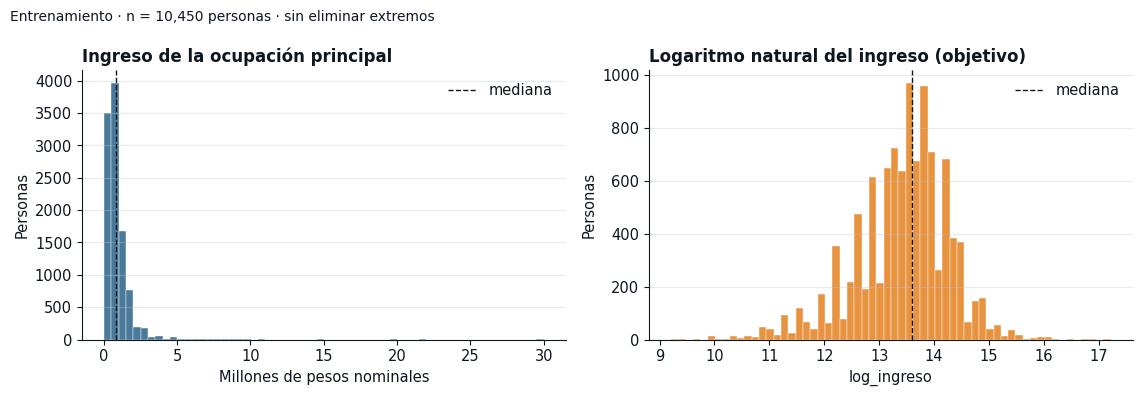

In [5]:
# Espacio de resolución — C4 · escalas y resumen
# Escribir aquí el código solicitado.

print("Resolucion punto 1")
variables = ["ingreso_principal_ars", "log_ingreso", "horas_semana"]
datos = entrenamiento[variables]
resumen = pd.DataFrame({
    "n": datos.count(),
    "media": datos.mean(),
    "mediana": datos.median(),
    "desvio_muestral": datos.std(ddof=1),                        # ddof=1 → desvío muestral
    "Q1": datos.quantile(0.25),                                 # primer cuartil
    "Q3": datos.quantile(0.75),                                  # segundo cuartil
    "IQR": datos.quantile(0.75) - datos.quantile(0.25),          # rango intercuartílico
})
display(resumen.round(2))
print("\n")

# 2) Figura de dos paneles: ingreso original vs. su logaritmo (sin borrar extremos)
fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.hist(entrenamiento["ingreso_principal_ars"] / 1e6, bins=60, color=AZUL, edgecolor="white", linewidth=0.3)
ax1.axvline(entrenamiento["ingreso_principal_ars"].median() / 1e6, color=TINTA, ls="--", lw=1, label="mediana")
ax1.set(title="Ingreso de la ocupación principal", xlabel="Millones de pesos nominales", ylabel="Personas")
ax1.legend(frameon=False)

ax2.hist(entrenamiento["log_ingreso"], bins=60, color=AMBAR, edgecolor="white", linewidth=0.3)
ax2.axvline(entrenamiento["log_ingreso"].median(), color=TINTA, ls="--", lw=1, label="mediana")
ax2.set(title="Logaritmo natural del ingreso (objetivo)", xlabel="log_ingreso", ylabel="Personas")
ax2.legend(frameon=False)

fig.suptitle(f"Entrenamiento · n = {len(entrenamiento):,} personas · sin eliminar extremos",
             x=0.01, ha="left", fontsize=10, color=TINTA)
plt.tight_layout()
plt.show()

**Interpretación.** Escribir entre tres y seis líneas a partir de las salidas, respondiendo la consigna.

El ingreso presenta una distribución asimétrica a la derecha dado que la mayoría de las personas se concentra en valores bajos, pero una cola de ingresos altos llega hasta los 30 millones, lo que eleva la media por encima de la mediana. El 50% central gana entre 400.000 y 1.200.000.

Las horas tienen mediana de 40 hs semanales, que coincide con una jornada típica de un trabajador estable en relación de dependencia, y una media inferior (36,4 hs) ya que el recorte incluye datos de personas que hacen jornadas parciales, changas, entre otros.

Al aplicar el escalado logarítmico la distribución se vuelve mucho más simétrica por lo que la media y la mediana quedan cerca 13,4 y 13,59 respectivamente, con una leve cola hacia la izquierda. Los picos del histograma reflejan que muchas personas declaran valores redondeados. Modelar en log nos conviene para que el error no esté concentrado en unas pocas personas con ingresos altos.


La segunda figura busca una asociación entre dedicación horaria y la escala que se modelará. Si se elige dispersión, la transparencia ayuda a ver concentraciones sin sustituir registros por promedios.

Representacion de las horas frente ingreso_log con medianas por intervalos



,n,q1,mediana,q3,mediana_en_pesos
horas_semana,,,,,
"[1, 20)",1332,11.70,12.30,12.90,220000.0
"[20, 35)",2871,12.90,13.30,13.71,600000.0
"[35, 49)",4834,13.38,13.76,14.15,950000.0
"[49, 168]",1413,13.30,13.75,14.15,940000.0


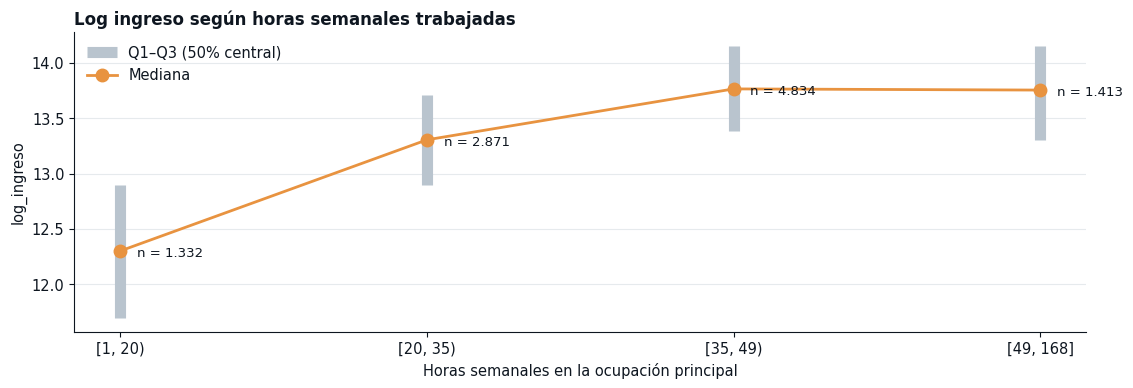

In [6]:
# Espacio de resolución — C4 · horas e ingreso
# Escribir aquí el código solicitado.


print("Representacion de las horas frente ingreso_log con medianas por intervalos\n")
# 1) Intervalos de horas: [1,20) [20,35) [35,49) [49,168]
#    Las horas son enteras, así que el corte en 169 con right=False deja el último cerrado en 168
cortes = [1, 20, 35, 49, 169]
etiquetas = ["[1, 20)", "[20, 35)", "[35, 49)", "[49, 168]"]
tramo_horas = pd.cut(entrenamiento["horas_semana"], bins=cortes, right=False, labels=etiquetas)

# 2) Tabla por intervalo: cantidad, cuartiles y mediana del log ingreso
por_tramo = entrenamiento.groupby(tramo_horas, observed=True)["log_ingreso"].agg(
    n="count",
    q1=lambda s: s.quantile(0.25),
    mediana="median",
    q3=lambda s: s.quantile(0.75),
)
por_tramo["mediana_en_pesos"] = np.exp(por_tramo["mediana"]).round(-3)   # sólo ilustrativo
assert por_tramo["n"].sum() == len(entrenamiento)                         # nadie queda fuera de los intervalos
display(por_tramo.round(2))
print("\n")

# 3) Figura: mediana por intervalo, con el 50% central (Q1–Q3) y la cantidad de personas
fig, ax = plt.subplots()
x = np.arange(len(por_tramo))
ax.vlines(x, por_tramo["q1"], por_tramo["q3"], color=GRIS, lw=8, label="Q1–Q3 (50% central)")
ax.plot(x, por_tramo["mediana"], color=AMBAR, marker="o", ms=9, lw=2, label="Mediana")
for xi, (med, n) in enumerate(zip(por_tramo["mediana"], por_tramo["n"])):
    ax.annotate(f"n = {n:,}".replace(",", "."), (xi, med), textcoords="offset points",
                xytext=(12, -4), color=TINTA, fontsize=9.5)
ax.set_xticks(x, por_tramo.index.astype(str))
ax.set(title="Log ingreso según horas semanales trabajadas",
       xlabel="Horas semanales en la ocupación principal", ylabel="log_ingreso")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación.** Escribir entre tres y seis líneas a partir de las salidas, respondiendo la consigna.

Vemos que tenemos un número más grande de personas en el rango [35-49] con una mediana de 950.000, que coinciden como comentamos anteriormente con las 40 hs semanales de los trabajos en relación de dependencia. La  mediana sube hasta este intervalo y se mantiene en el último intervalo, sube proporcionalmente mucho más en el del primer al segundo rango. Vale la pena aclarar que esto es una asociación y que no necesariamente trabajar más horas implica ganar más.

Observamos que el IQR del primer intervalo es más grande que en los otros, lo que significa que la dispersión es mayor en el rango de quienes trabajan pocas horas pudiendo ser desde changas o trabajos a jornada parcial.

La elección de las medianas por intervalos es debido a que es más fácil de entender para personal no técnico y podemos visualizar la dispersión mediante el IQR.


La tercera figura mantiene los sectores como categorías. Se acompaña con su cantidad de personas para distinguir grupos frecuentes y poco representados.

Comparacion log_ingreso mediante boxplots



,n,mediana,IQR,minimo,maximo,% del total
sector,,,,,,
Privado,8029,13.46,1.01,9.21,17.22,76.8
Estatal,2314,13.71,0.62,10.60,16.06,22.1
Otro tipo,107,13.71,1.14,10.82,14.91,1.0


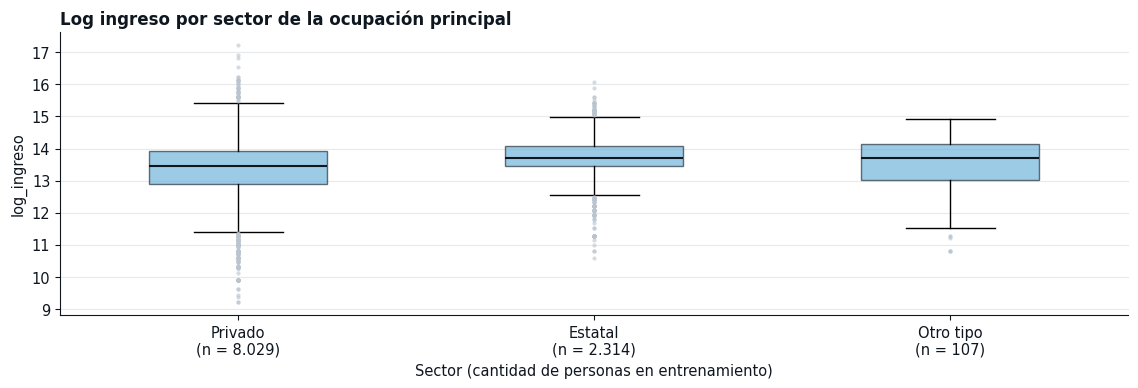

In [7]:
# Espacio de resolución — C4 · sectores
# Escribir aquí el código solicitado.

print("Comparacion log_ingreso mediante boxplots\n")
# 1) Resumen por sector: cantidad, mediana, IQR y rango (ordenado por tamaño de grupo)
resumen_sector = entrenamiento.groupby("sector")["log_ingreso"].agg(
    n="count",
    mediana="median",
    IQR=lambda s: s.quantile(0.75) - s.quantile(0.25),
    minimo="min",
    maximo="max",
).sort_values("n", ascending=False)
resumen_sector["% del total"] = (100 * resumen_sector["n"] / len(entrenamiento)).round(1)
display(resumen_sector.round(2))
print("\n")
# 2) Boxplots del log ingreso por sector, con la cantidad de personas en cada etiqueta
orden = resumen_sector.index
grupos = [entrenamiento.loc[entrenamiento["sector"] == s, "log_ingreso"] for s in orden]
etiquetas = [f"{s}\n(n = {n:,})".replace(",", ".") for s, n in resumen_sector["n"].items()]

fig, ax = plt.subplots()
cajas = ax.boxplot(grupos, tick_labels=etiquetas, patch_artist=True, widths=0.5,
                   medianprops=dict(color=TINTA, lw=1.5),
                   flierprops=dict(marker="o", ms=3, markerfacecolor=GRIS, markeredgecolor="none", alpha=0.6))
for caja in cajas["boxes"]:
    caja.set(facecolor=CIAN, alpha=0.6, edgecolor=TINTA)
ax.set(title="Log ingreso por sector de la ocupación principal",
       xlabel="Sector (cantidad de personas en entrenamiento)", ylabel="log_ingreso")
plt.tight_layout()
plt.show()

**Interpretación.** Escribir entre tres y seis líneas a partir de las salidas, respondiendo la consigna.

Podemos observar que la mayor parte de personas trabaja en el sector privado (77%) mientras que el restante 23% trabaja en el estado o en otro tipo, que queda muy subrepresentado al estar conformado por 107 personas por lo que tanto su mediana como dispersión son poco confiables. Pueden ser personas que trabajan en cooperativas u otro tipo de organizaciones que no son ni estatales ni privadas.

Así y todo el sector con la mediana más alta es el estado (comparte mediana con otro tipo), donde la diferencia en unidades logaritmos respecto del privado es chica. (13,71 contra 13,46 respectivamente). Además el estado es la caja con menor dispersión siendo “Otro tipo” el más variable de los tres

La diferencia entre los sectores puede deberse a las diferencias en la composición de cada uno (como la educación, cantidad de horas trabajadas, etc) y no necesariamente al sector en sí.

Observando las tres figuras considero que el agregar horas, sector así como otra información laboral me pueden permitir estimar de mejor manera el ingreso de la persona ya que vimos un incremento en la mediana al aumentar las horas trabajadas y respecto del sector no hemos evidenciado diferencias grandes aun.


# 5. Preparar sin aprender de la evaluación
## 5.1 Consigna C5 — Fijar una lista de variables y explicar el tratamiento

Mantener las tres variables `BASE`. Elegir **dos o tres** variables de `MENU_LABORAL` para la ampliación, usando el EDA y el contexto; justificar la lista antes de C6. La solución que incluya las tres responde directamente la pregunta completa. Si se omite una, delimitar la conclusión a las incluidas. No buscar listas diferentes según el error de validación.

Conservar filas y extremos válidos del recorte. El escalado numérico y la codificación one-hot se incorporan dentro de cada secuencia de transformaciones y modelo y se aprenden exclusivamente con entrenamiento. No imputar el objetivo ni recodificar categorías como números ordenados. La función provista construye la preparación; no ajusta modelos.

Crear una tabla que identifique variable original, tratamiento y razón. Informar cuántas columnas resultan al ajustar una copia del preparador en entrenamiento. Esta copia sirve para inspección; cada modelo utilizará su propio preparador.

In [8]:
def crear_preparador(columnas):
    """Soporte de codificación: se ajusta sólo al llamar fit en entrenamiento."""
    categoricas = [c for c in columnas if c in ["sector", "rama_agrupada"]]
    numericas = [c for c in columnas if c not in categoricas]
    transformadores = [("num", StandardScaler(), numericas)]
    if categoricas:
        transformadores.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas))
    return ColumnTransformer(transformadores, remainder="drop")

**Interpretación.** One-hot produce indicadores de pertenencia y evita imponer un orden artificial. Si aparece una categoría nueva en evaluación, sus indicadores serán cero; el modelo no aprende de esa aparición. La ayuda conserva todas las categorías observadas: no se interpretarán sus coeficientes individuales como efectos causales.

In [9]:
# Espacio de resolución — C5 · decisiones y dimensión
# Escribir aquí el código solicitado.

# 1) Lista fijada ANTES de comparar en validación
LABORAL_ELEGIDAS = ["horas_semana", "sector", "rama_agrupada"]
AMPLIADA = BASE + LABORAL_ELEGIDAS

# 2) Tabla de decisiones: variable, tratamiento y razón
decisiones = pd.DataFrame([
    ("anios_educacion",       "Base",    "Numérica → estandarización", "Aproximacion por convencion de la educacion, es  predictor clasico del ingreso"),
    ("experiencia_potencial", "Base",    "Numérica → estandarización", "Aproxima cuanto tiempo lleva la persona en el mercado laboral"),
    ("experiencia_cuadrado",  "Base",    "Numérica → estandarización", "Curva cuadratica representando la razon de cambio no lineal en ingresos a medida que la persona gana mas experiencia"),
    ("horas_semana",          "Laboral", "Numérica → estandarización", "La mediana sube mucho al aumentar las hs semanales, planchandose alrrededor de las horas correspondientes a una jornada completa"),
    ("sector",                "Laboral", "Categórica → one-hot",       "No podemos codificar como  numeros al no tener un orden natural, debido a eso usamos one-hot"),
    ("rama_agrupada",         "Laboral", "Categórica → one-hot",       "No se exploro aun"),
], columns=["variable", "grupo", "tratamiento", "razón"])
display(decisiones)
print("\n")

# 3) Copia del preparador ajustada SÓLO con entrenamiento, para inspeccionar la dimensión
preparador_inspeccion = crear_preparador(AMPLIADA).fit(entrenamiento[AMPLIADA])
nombres = preparador_inspeccion.get_feature_names_out()
dimension = pd.Series({
    "numéricas estandarizadas": sum(n.startswith("num__") for n in nombres),
    "indicadores de sector": sum(n.startswith("cat__sector_") for n in nombres),
    "indicadores de rama": sum(n.startswith("cat__rama_agrupada_") for n in nombres),
    "total de columnas": len(nombres),
}, name="columnas")
display(dimension.to_frame())

,variable,grupo,tratamiento,razón
0,anios_educacion,Base,Numérica → estandarización,"Aproximacion por convencion de la educacion, e..."
1,experiencia_potencial,Base,Numérica → estandarización,Aproxima cuanto tiempo lleva la persona en el ...
2,experiencia_cuadrado,Base,Numérica → estandarización,Curva cuadratica representando la razon de cam...
3,horas_semana,Laboral,Numérica → estandarización,La mediana sube mucho al aumentar las hs seman...
4,sector,Laboral,Categórica → one-hot,No podemos codificar como numeros al no tener...
5,rama_agrupada,Laboral,Categórica → one-hot,No se exploro aun


,columnas
numéricas estandarizadas,4
indicadores de sector,3
indicadores de rama,19
total de columnas,26


**Interpretación.** Escribir entre tres y seis líneas a partir de las salidas, respondiendo la consigna.

Elegi usar las tres variables del MENU_LABORAL ya que me permiten responder la pregunta central basandome en lo que observe en puntos antreriores las horas evidenciaron un gradiente claro, el sector presenta diferencias aunque chicas y la rama aun no la hemos explorado.

En este caso, las variables numericas se estandarizan al tener escalas distintas dado que Ridge penaliza el tamano de los coeficientes y las categoricas usan one-hot al no tener un orden definido.

El preparador ajustado sólo con entrenamiento produce 26 columnas: 4 numéricas estandarizadas, 3 indicadores de sector y 19 indicadores de rama. Las columnas numéricas y los indicadores de sector se estiman con miles de personas, pero algunas ramas tienen muy pocos casos en entrenamiento por lo que sus coeficientes son poco confiables.

# 6. Comparar sin abrir prueba
## 6.1 Consigna C6 — Medir la mejora frente a dos referencias

La métrica principal es **RMSE del log ingreso** (raíz del error cuadrático medio; *root mean squared error*), la raíz del promedio de los errores al cuadrado entre el logaritmo observado y su predicción. Menor es mejor; sus unidades son logarítmicas, no pesos ni porcentajes. Informar también MAE del log ingreso (error absoluto medio; *mean absolute error*), promedio de errores absolutos. No cambiar de métrica para elegir al ganador.

| Papel | Método y variables | Configuraciones |
|---|---|---|
| Referencia constante | Media del log ingreso de entrenamiento | Una |
| Referencia económica | Regresión lineal con `BASE` | Una |
| Candidato ampliado | Regresión lineal con `BASE` y la lista laboral fijada | Una |
| Candidatos regularizados | Ridge con exactamente las mismas variables ampliadas | `alpha` = 0,1; 10; 100 |

No agregar configuraciones ni algoritmos. Hay cuatro candidatos principales además de las referencias; la lineal base también puede conservarse como elección final si gana. Usar `Pipeline` y un preparador nuevo para cada regresión lineal o Ridge; la referencia constante puede usar directamente `DummyRegressor(strategy="mean")`, porque no utiliza predictores. `alpha` controla la intensidad de la penalización Ridge: valores mayores reducen más los coeficientes, lo que no garantiza menor error fuera de entrenamiento.

Preparar una tabla con nombre, variables, configuración, RMSE de entrenamiento, RMSE de validación y MAE de validación. Calcular `RMSE_validacion_modelo − RMSE_validacion_lineal_base`: un resultado negativo indica menor error que la lineal base. **Valor público del modelo de referencia (baseline) constante:** la media de entrenamiento obtiene RMSE de validación **0,856951** (redondeado a seis decimales) en este paquete. Se usa para comprobar el procedimiento, no como nota mínima. Las referencias deben calcularse, no copiarse.

Usar sólo entrenamiento para ajustar (`fit`); validación se utiliza exclusivamente para predecir (`predict`). Comparar también brechas entre ajuste y validación.

In [10]:
# Espacio de resolución — C6 · comparación
# Escribir aquí el código solicitado.

def rmse(y, pred):
    return np.sqrt(mean_squared_error(y, pred))

y_ent = entrenamiento[OBJETIVO]
y_val = validacion[OBJETIVO]

# 1) Menú cerrado de modelos: (nombre, variables, configuración, estimador sin ajustar)
#    Cada lineal/Ridge tiene su PROPIO preparador nuevo dentro del Pipeline
candidatos = [
    ("Media (referencia)", [],       "strategy='mean'", DummyRegressor(strategy="mean")),
    ("Lineal base",        BASE,     "—",               Pipeline([("prep", crear_preparador(BASE)),     ("modelo", LinearRegression())])),
    ("Lineal ampliada",    AMPLIADA, "—",               Pipeline([("prep", crear_preparador(AMPLIADA)), ("modelo", LinearRegression())])),
    ("Ridge α=0,1",        AMPLIADA, "alpha=0.1",       Pipeline([("prep", crear_preparador(AMPLIADA)), ("modelo", Ridge(alpha=0.1))])),
    ("Ridge α=10",         AMPLIADA, "alpha=10",        Pipeline([("prep", crear_preparador(AMPLIADA)), ("modelo", Ridge(alpha=10))])),
    ("Ridge α=100",        AMPLIADA, "alpha=100",       Pipeline([("prep", crear_preparador(AMPLIADA)), ("modelo", Ridge(alpha=100))])),
]

# 2) Ajustar SÓLO con entrenamiento; validación se usa sólo para predecir
modelos_ajustados = {}
filas = []
for nombre, variables, config, estimador in candidatos:
    X_ent = entrenamiento[variables] if variables else np.zeros((len(entrenamiento), 1))  # la media no usa predictores
    X_val = validacion[variables] if variables else np.zeros((len(validacion), 1))
    estimador.fit(X_ent, y_ent)
    pred_ent = estimador.predict(X_ent)
    pred_val = estimador.predict(X_val)
    modelos_ajustados[nombre] = estimador          # se guardan ajustados para C7
    filas.append({
        "modelo": nombre,
        "variables": "ninguna" if not variables else ("BASE" if variables == BASE else "BASE + horas, sector, rama"),
        "configuración": config,
        "RMSE_entrenamiento": rmse(y_ent, pred_ent),
        "RMSE_validacion": rmse(y_val, pred_val),
        "MAE_validacion": mean_absolute_error(y_val, pred_val),
    })

comparacion = pd.DataFrame(filas).set_index("modelo")
rmse_base = comparacion.loc["Lineal base", "RMSE_validacion"]
comparacion["dif_vs_lineal_base"] = comparacion["RMSE_validacion"] - rmse_base       # negativo = mejor que la base
comparacion["brecha_val_menos_ent"] = comparacion["RMSE_validacion"] - comparacion["RMSE_entrenamiento"]
display(comparacion.round(6))

# 3) Control de la cátedra: la media debe dar 0,856951 en validación
print("\nRMSE validación de la media:", round(comparacion.loc["Media (referencia)", "RMSE_validacion"], 6))
assert round(comparacion.loc["Media (referencia)", "RMSE_validacion"], 6) == 0.856951

,variables,configuración,RMSE_entrenamiento,RMSE_validacion,MAE_validacion,dif_vs_lineal_base,brecha_val_menos_ent
modelo,,,,,,,
Media (referencia),ninguna,strategy='mean',0.857855,0.856951,0.656578,0.061706,-0.000904
Lineal base,BASE,—,0.798457,0.795245,0.601749,0.000000,-0.003212
Lineal ampliada,"BASE + horas, sector, rama",—,0.655233,0.656077,0.490848,-0.139169,0.000844
"Ridge α=0,1","BASE + horas, sector, rama",alpha=0.1,0.655233,0.656076,0.490848,-0.139169,0.000843
Ridge α=10,"BASE + horas, sector, rama",alpha=10,0.655308,0.656090,0.490932,-0.139155,0.000782
Ridge α=100,"BASE + horas, sector, rama",alpha=100,0.657627,0.658008,0.492833,-0.137237,0.000381



RMSE validación de la media: 0.856951


**Interpretación.** Escribir entre tres y seis líneas a partir de las salidas, respondiendo la consigna.

Podemos observar que la lineal base presenta una mejora ligera conta la media de referencia pero mas grande es el salto de la lineal base a la lineal ampliada, siendo de mas del doble.

Pero cuando pasamos a ridge, si lo comparamos contra la lineal ampliada el RMSE va empeorando a medida que aumentamos el alpha. Esto significa que la lineal ampliada no sobreajusta por lo que no queda mucho que corregir  con la penalizacion de ridge.

Por ultimo, si vemos que al pasa de la media a la lineal ampliada se aumenta la brecha entrenamiento-validacion, pero muy ligeramente. No hay senales de sobreajuste en ningun modelo.

# 7. Congelar una elección verificable
## 7.1 Consigna C7 — Registrar antes de evaluar

Elegir entre lineal base, lineal ampliada y Ridge por menor RMSE de validación redondeado a seis decimales. **Regla previa de desempate:** a igual valor redondeado, preferir lineal base, luego lineal ampliada y luego Ridge con mayor `alpha`.

Registrar nombre, lista de variables, tratamiento, `alpha` cuando corresponda y RMSE de validación. Conservar el objeto ya ajustado como `modelo_elegido`. Justificar la elección en cuatro a seis líneas, sin consultar prueba ni reajustar con validación. La diferencia minúscula entre modelos no debe narrarse como una mejora importante.

In [11]:
# Espacio de resolución — C7 · selección congelada
# Escribir aquí el código solicitado.

# === C7 · Selección congelada ===

# 1) Candidatos elegibles (la media es sólo referencia) y regla de desempate fijada antes
prioridad_desempate = {"Lineal base": 0, "Lineal ampliada": 1,
                       "Ridge α=100": 2, "Ridge α=10": 3, "Ridge α=0,1": 4}   # Ridge: mayor alpha primero
elegibles = comparacion.loc[list(prioridad_desempate)].copy()
elegibles["RMSE_val_6d"] = elegibles["RMSE_validacion"].round(6)
elegibles["desempate"] = elegibles.index.map(prioridad_desempate)
print("Desempate lineal base - lineal ampliada y Ridge\n")

# 2) Menor RMSE redondeado; ante empate, menor número de desempate
ranking = elegibles.sort_values(["RMSE_val_6d", "desempate"])
display(ranking[["configuración", "RMSE_val_6d", "desempate"]])
nombre_elegido = ranking.index[0]
print("\n")

# 3) Congelar: se conserva el objeto YA ajustado con entrenamiento (no se reajusta con validación)
modelo_elegido = modelos_ajustados[nombre_elegido]
registro_eleccion = pd.Series({
    "modelo": nombre_elegido,
    "variables": ", ".join(AMPLIADA if nombre_elegido != "Lineal base" else BASE),
    "tratamiento": "StandardScaler en numéricas + OneHotEncoder en sector y rama (aprendidos en entrenamiento)",
    "alpha": comparacion.loc[nombre_elegido, "configuración"],
    "RMSE_validacion (6 decimales)": f"{elegibles.loc[nombre_elegido, 'RMSE_val_6d']:.6f}",
}, name="elección congelada")
display(registro_eleccion.to_frame())

Desempate lineal base - lineal ampliada y Ridge



,configuración,RMSE_val_6d,desempate
modelo,,,
"Ridge α=0,1",alpha=0.1,0.656076,4
Lineal ampliada,—,0.656077,1
Ridge α=10,alpha=10,0.656090,3
Ridge α=100,alpha=100,0.658008,2
Lineal base,—,0.795245,0


,elección congelada
modelo,"Ridge α=0,1"
variables,"anios_educacion, experiencia_potencial, experi..."
tratamiento,StandardScaler en numéricas + OneHotEncoder en...
alpha,alpha=0.1
RMSE_validacion (6 decimales),0.656076


**Interpretación.** Escribir entre tres y seis líneas a partir de las salidas, respondiendo la consigna.

Al buscar menor error RMSE redondeado a seis decimales no nos queda otra que elegir ridge con alpha = 0,1 por una diferencia de 0,000001 respecto al lineal ampliado lo cual no implica una mejora considerable al encontrarnos con una diferencia tan chica, pero como tal no aplica realizar un desempate.

De todas formas, ridge con un alpha tan chico ofrece una penalizacion igualmente pequena que casi no modifica los coeficientes. Yendo en concordancia con lo que resolvimos en la consigna anterior, dado que la lineal ampliada no presentaba sobrreajuste, no quedaba mucho relevante sobre lo que corregir.

Sin embargo, la mejora importante aca viene del agregado de las variables laborales y no necesariamente de la regularizacion. El modelo se conserva ajustado solo con entrenamiento sin reajustar ni consultar prueba.



# 8. Evaluar una vez en viviendas reservadas
## 8.1 Abrir prueba después de C7

Ejecutar la siguiente carga sólo después de completar el registro de elección. Las etiquetas están en el paquete por razones prácticas; respetar el orden forma parte del protocolo. La comprobación garantiza que ninguna vivienda de prueba apareció en ajuste o validación.

In [12]:
prueba = pd.read_csv(RUTA_DATOS / "prueba.csv")
assert set(prueba.grupo_vivienda).isdisjoint(entrenamiento.grupo_vivienda)
assert set(prueba.grupo_vivienda).isdisjoint(validacion.grupo_vivienda)
assert set(prueba.id_persona).isdisjoint(entrenamiento.id_persona)
print("Prueba reservada:",len(prueba),"personas /",prueba.grupo_vivienda.nunique(),"viviendas")

Prueba reservada: 2272 personas / 1479 viviendas


**Interpretación.** El conjunto final permite examinar viviendas distintas dentro del recorte del trimestre. No representa automáticamente otro período, una nueva ciudad ni personas que no respondieron ingreso.

## 8.2 Consigna C8 — Evaluar la elección y las referencias

Calcular RMSE y MAE del log ingreso en prueba para el modelo elegido, la media y la lineal base. No evaluar nuevamente todo el menú para seleccionar otro candidato. Comparar las diferencias observadas en validación y prueba.

Crear una figura de log ingreso observado frente al estimado por el elegido, con línea de igualdad y ejes en la misma escala. Explicar qué patrón sería ideal y qué errores se observan. No reentrenar ni corregir la elección al mirar este gráfico.

Evaluar eleccion y referencias



,RMSE_validacion,RMSE_prueba,MAE_validacion,MAE_prueba,cambio_RMSE_prueba_menos_val
modelo,,,,,
"Elegido (Ridge α=0,1)",0.656076,0.625361,0.490848,0.480580,-0.030715
Media (referencia),0.856951,0.827922,0.656578,0.644637,-0.029029
Lineal base,0.795245,0.768168,0.601749,0.591168,-0.027077





Diferencia de RMSE respecto de la lineal base (negativo = menor error)



,dif_vs_base_validacion,dif_vs_base_prueba
modelo,,
"Elegido (Ridge α=0,1)",-0.139169,-0.142807
Media (referencia),0.061706,0.059754
Lineal base,0.000000,0.000000


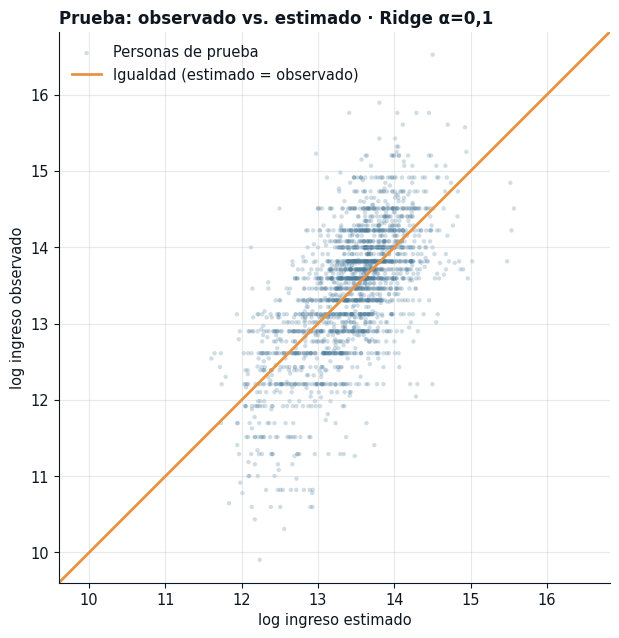

In [13]:
# Espacio de resolución — C8 · prueba final
# Escribir aquí el código solicitado.
print("Evaluar eleccion y referencias\n")
y_prueba = prueba[OBJETIVO]

# 1) Evaluar UNA vez en prueba: el elegido + las dos referencias
a_evaluar = {
    f"Elegido ({nombre_elegido})": (modelo_elegido, AMPLIADA),
    "Media (referencia)": (modelos_ajustados["Media (referencia)"], []),
    "Lineal base": (modelos_ajustados["Lineal base"], BASE),
}
filas = []
predicciones_prueba = {}
for nombre, (modelo, variables) in a_evaluar.items():
    X_prueba = prueba[variables] if variables else np.zeros((len(prueba), 1))
    pred = modelo.predict(X_prueba)                      # sólo predict: nada se vuelve a ajustar
    predicciones_prueba[nombre] = pred
    nombre_val = nombre_elegido if nombre.startswith("Elegido") else nombre
    filas.append({
        "modelo": nombre,
        "RMSE_validacion": comparacion.loc[nombre_val, "RMSE_validacion"],
        "RMSE_prueba": rmse(y_prueba, pred),
        "MAE_validacion": comparacion.loc[nombre_val, "MAE_validacion"],
        "MAE_prueba": mean_absolute_error(y_prueba, pred),
    })
evaluacion_prueba = pd.DataFrame(filas).set_index("modelo")
evaluacion_prueba["cambio_RMSE_prueba_menos_val"] = evaluacion_prueba["RMSE_prueba"] - evaluacion_prueba["RMSE_validacion"]
display(evaluacion_prueba.round(6))
print("\n")

# 2) Diferencias frente a la lineal base: ¿se mantienen de validación a prueba?
mejoras = pd.DataFrame({
    "dif_vs_base_validacion": evaluacion_prueba["RMSE_validacion"] - evaluacion_prueba.loc["Lineal base", "RMSE_validacion"],
    "dif_vs_base_prueba": evaluacion_prueba["RMSE_prueba"] - evaluacion_prueba.loc["Lineal base", "RMSE_prueba"],
})
print("\nDiferencia de RMSE respecto de la lineal base (negativo = menor error)\n")
display(mejoras.round(6))
print("\n")

# 3) Observado vs. estimado por el elegido, con línea de igualdad y ejes en la misma escala
pred_elegido = predicciones_prueba[f"Elegido ({nombre_elegido})"]
lim = (min(y_prueba.min(), pred_elegido.min()) - 0.3, max(y_prueba.max(), pred_elegido.max()) + 0.3)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(pred_elegido, y_prueba, s=10, alpha=0.25, color=AZUL, edgecolors="none", label="Personas de prueba")
ax.plot(lim, lim, color=AMBAR, lw=2, label="Igualdad (estimado = observado)")
ax.set(xlim=lim, ylim=lim, aspect="equal",
       title=f"Prueba: observado vs. estimado · {nombre_elegido}",
       xlabel="log ingreso estimado", ylabel="log ingreso observado")
ax.grid(True, axis="both")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación.** Escribir entre tres y seis líneas a partir de las salidas, respondiendo la consigna.

El RMSE en prueba mejora respecto al de validación para los tres modelos en un gradiente parecido, por lo que podemos decir que la prueba es un conjunto más “predecible”. El modelo elegido (Ridge con alpha = 0,1) mantiene su ventaja respecto a la lineal base e incluso crece levemente.

Si el modelo fuera perfecto los datos seguirán una igualdad entre lo estimado y lo observado, pero en el gráfico no se observa así. Para ingresos altos los puntos quedan por encima de la línea, por lo que el modelo los subestima contrario a los ingresos bajos que quedan por debajo de la línea y el modelo los sobreestima. Se observan estimaciones en el rango [11,5 - 15,5] y valores observados entre [10 - 16,5]

Otro detalle, se evidencia mucha concentración en puntos exactos del gráfico, como líneas horizontales que coinciden con valores de ingresos redondos como pudimos observar en puntos anteriores del proyecto

Un punto importante, para el gráfico no se entrenó ni se cambió la elección.


# 9. Explicar errores sin corregir sobre prueba
## 9.1 Consigna C9 — Dos personas y diferencias por región

Definir residuo como log ingreso observado menos predicho. Mostrar los dos registros con mayor error absoluto, sus variables laborales, ingreso observado, predicción logarítmica y signo del residuo. Explicar qué significa sobreestimar o subestimar; proponer una explicación posible señalando qué información falta para comprobarla.

Calcular cantidad de personas y RMSE por región, sin ponderación. Indicar si grupos con poco soporte requieren cautela. No atribuir diferencias regionales a causas identificadas ni aplicar correcciones posteriores. No publicar identificadores originales de la EPH: los IDs del paquete son suficientes.

In [14]:
# Espacio de resolución — C9 · errores y grupos
# Escribir aquí el código solicitado.

# 1) Residuo = observado − predicho (en log). Positivo → el modelo SUBESTIMA; negativo → SOBREESTIMA
print("Registros con mayor error absoluto\n")
errores = prueba[["id_persona", "region", "edad_anios", "nivel_educativo", "horas_semana",
                  "sector", "rama_agrupada", "categoria_ocupacional", "ingreso_principal_ars", OBJETIVO]].copy()
errores["log_predicho"] = pred_elegido
errores["residuo"] = errores[OBJETIVO] - errores["log_predicho"]
errores["error_absoluto"] = errores["residuo"].abs()
errores["signo"] = np.where(errores["residuo"] > 0, "+ (subestima)", "− (sobreestima)")
errores["ingreso_estimado_ilustrativo"] = np.exp(errores["log_predicho"]).round(-3)

# 2) Los dos registros con mayor error absoluto (IDs del paquete, no de la EPH)
peores = errores.nlargest(2, "error_absoluto")
display(peores.set_index("id_persona").T)

# 3) Cantidad de personas y RMSE por región (sin ponderar)
por_region = errores.groupby("region").agg(
    n=("residuo", "size"),
    RMSE=("residuo", lambda r: np.sqrt(np.mean(r ** 2))),
    residuo_medio=("residuo", "mean"),
).sort_values("RMSE", ascending=False)
por_region.loc["Total prueba"] = [len(errores), np.sqrt(np.mean(errores["residuo"] ** 2)), errores["residuo"].mean()]
por_region["n"] = por_region["n"].astype(int)
print("\nError del modelo elegido por región (prueba, sin ponderar)\n")
display(por_region.round(4))

Registros con mayor error absoluto



id_persona,P03126,P00862
region,Gran Buenos Aires,Pampeana
edad_anios,56,62
nivel_educativo,Secundaria completa,Secundaria incompleta
horas_semana,30,12
sector,Privado,Privado
rama_agrupada,Construcción,Hogares empleadores
categoria_ocupacional,Cuenta propia,Asalariado
ingreso_principal_ars,7000000,20000
log_ingreso,15.761421,9.903488
log_predicho,13.408452,12.236148



Error del modelo elegido por región (prueba, sin ponderar)



,n,RMSE,residuo_medio
region,,,
Gran Buenos Aires,341,0.6844,0.0992
Patagonia,253,0.6725,0.3587
Pampeana,684,0.6336,0.0554
Noreste,167,0.6057,-0.2012
Noroeste,617,0.5849,-0.1899
Cuyo,210,0.5665,-0.0855
Total prueba,2272,0.6254,-0.0028


**Interpretación.** Escribir entre tres y seis líneas a partir de las salidas, respondiendo la consigna.

El residuo es la diferencia matemática entre el valor observado y el valor predicho. Si este es positivo significa que la persona ganó más de lo estimado (subestimación) y por el contrario sería una sobreestimación.

Los dos registros con peor error absoluto son:

P03126 → Es un cuentapropista en construcción que trabajó 30 horas y ganó 7.000.000 mientras que el modelo estimó un ingreso de 666.000, encontrándonos en un caso de subestimación fuerte. Hay cierta información que el modelo no tiene y que podrían explicar la diferencia como si es dueño de una empresa, tipo de tarea, si dirige operaciones, entre otros.

P00862 → Una asalariada que realiza trabajos domésticos que trabajo 12 horas y gano 20.000 mientras que el modelo estimó un ingreso de 206.000, encontrándonos con un caso de sobreestimación. La explicación que podemos encontrar ante un ingreso tan bajo es un valor hora muy bajo, actividad informal o bien que haya un problema en como se declaró el ingreso, para comprobarlo haría falta conocer esta información.

La región con mayor error es el Gran Buenos Aires mientras que la que presenta el menor RMSE es Cuyo. Me resulta llamativo el alto valor de residuo medio en la patagonia (0,3587) comparado con las otras regiones, esto significa que el modelo tiende a subestimar el ingreso de una persona que trabaja en esta región posiblemente porque los sueldos suelen ser mayores y la región no es una variable del modelo.

Por último, existen regiones con menor representación que otras como son patagonia (253), cuyo (210) y el noreste (167) por lo que quedan subrepresentadas respecto del resto de regiones volviendo su RMSE menos estable partiendo de que todo se calcula sin ponderar. Entonces si, los grupos con poco soporte requieren cautela.


# 10. Responder y entregar
## 10.1 Consigna C10 — Síntesis de 200–300 palabras

Responder la pregunta central con evidencia de validación y prueba. Distinguir el aporte conjunto de variables laborales de la regularización; explicar al menos dos límites y proponer una mejora futura que no se ejecute sobre esta prueba.

Antes de entregar: reiniciar kernel, ejecutar todas las celdas en orden, verificar ausencia de errores, conservar rutas relativas, incluir las interpretaciones y registrar fuentes consultadas. No agregar otro informe. El registro de C7 debe corresponder al modelo efectivamente evaluado.

Escribir la respuesta en este espacio.

Podemos confirmar que agregar horas, sector y rama ayuda a reducir el error en la estimación con los valores obtenidos en validación y prueba.

En validación pasamos de una lineal base en 0,795 a ridge con alpha = 0,1 obteniendo un error de 0,656. Evidenciando una reducción relativa del 17%.
Y en prueba pasamos de base en 0,768 a ridge con alpha en 0,1 obteniendo un error de 0,625. Evidenciando una reducción del error relativa del 18%.

La principal mejora viene del agregado de variables, ya que la mejora que vemos desde la lineal ampliada a ridge con alpha = 0,1 es muy poca debido (en este caso la diferencia es de 0,000001) a que no hay sobreajuste y como tal no queda mucho por corregir, entonces la penalización al tener un alpha chico es igualmente muy chica.

Existen varios límites dentro del proyecto, los que me parecieron más interesantes para explicar son:

Por un lado el sesgo de ingreso subestimado en la patagonia, da un residuo medio muy elevado posiblemente porque región no es una variable del modelo, que entonces les estima un ingreso cercano al promedio nacional. Lo que hace que las personas de la patagonia tiendan a estar en promedio subestimadas respecto a su salario.

Por el otro, los ingresos redondeados cuando las personas declaran su ingreso muchos tienden a redondear el valor haciendo que encontremos muchas personas en cifras redondas. Esto agrega imprecisión al objetivo que el modelo no puede captar.

Si tuviera que implementar una mejora futura del proyecto sería incluir región (con one-hot al igual que el sector) como predictor para que el ponelo pueda discernir diferencias de nivel entre distintas regiones del país y evaluarlo en un conjunto de datos nuevo dado que esta prueba ya fue utilizada.



## Referencias y trazabilidad

- Instituto Nacional de Estadística y Censos (INDEC). *EPH: bases de microdatos, cuarto trimestre de 2025*. [Portal oficial](https://www.indec.gob.ar/Institucional/Indec/BasesDeDatos). Fuente del dato primario: Instituto Nacional de Estadística y Censos (INDEC).
- INDEC. *Diseño de registro y estructura para las bases preliminares, 4T2025*. [Documento oficial](https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/EPH_registro_4T2025.pdf).
- INDEC (2018). *CAES Mercosur 1.0, notas explicativas*. [Clasificador](https://www.indec.gob.ar/ftp/cuadros/menusuperior/clasificadores/notas_explicativas_caes_v2018.pdf). Consulta docente para agrupar ramas; no es lectura completa requerida.

Los CSV se derivaron del archivo oficial con filtros, recodificaciones y partición documentados en `DICCIONARIO.md` y `FUENTES_Y_LICENCIAS.md`. Consulta de fuentes: 18/09/2026. No se fabricaron nulos ni errores para crear una tarea de limpieza.